# Kaliforniya Konut Değerlerini Tahmin Etme (Regresyon)

**Yapay Zekâya Giriş · Makine Öğrenmesi Haftası**

| | |
|---|---|
| **Veri seti** | California Housing (1990 ABD nüfus sayımı): 20.640 bölge, 8 özellik |
| **Veri kaynağı** | scikit-learn kütüphanesindeki hazır veri seti |
| **Görev** | Regresyon: bir bölgedeki ortalama ev değerini tahmin etmek |
| **Öğrenme türü** | Gözetimli öğrenme, etiketli veri |
| **Algoritmalar** | Doğrusal Regresyon, Karar Ağacı, Rastgele Orman |

### Bu uygulamada yapacaklarımız
1. Kütüphaneleri yüklemek ve her birinin görevini görmek
2. Hazır veri setini yüklemek ve tanımak
3. Grafiklerle özellikler ile ev değeri arasındaki ilişkiyi incelemek
4. Tek özellikli doğrusal regresyon ile öğrenilen doğruyu görmek
5. Tüm özelliklerle modeller kurmak ve MAE, RMSE, R² ile karşılaştırmak
6. Aşırı öğrenmeyi bir grafikte görmek
7. Hangi özelliklerin önemli olduğunu incelemek
8. Yeni bir bölge için tahmin yapmak

Birinci uygulamadan farkı: Orada tahmin ettiğimiz şey bir **kategori** (çiçek türü) idi. Burada tahmin ettiğimiz şey bir **sayı** (ev değeri). Bu yüzden değerlendirme ölçütleri de değişiyor.

---
## 1. Kütüphaneleri yüklemek

| Kütüphane | Ne işe yarar? | Bu uygulamada neden kullanıyoruz? |
|---|---|---|
| **pandas** (`pd`) | Tablo verisiyle çalışma | Veriyi tablo olarak incelemek, sonuçları tablo hâlinde göstermek |
| **NumPy** (`np`) | Hızlı sayısal işlemler | Karekök almak (RMSE için), sayı aralıkları üretmek, en büyük değerin yerini bulmak |
| **Matplotlib** (`plt`) | Temel grafik çizimi | Dağılım grafikleri, harita benzeri çizim, çizgi grafikleri |
| **Seaborn** (`sns`) | İstatistiksel grafikler | Histogram ve korelasyon ısı haritası |
| **scikit-learn** (`sklearn`) | Makine öğrenmesi araçları | Veri setini yüklemek, veriyi bölmek, modelleri eğitmek ve ölçmek |

In [1]:
import pandas as pd                 # tablo verisi: inceleme, sütun seçme, sonuç tabloları
import numpy as np                  # sayısal işlemler: karekök, sayı aralıkları
import matplotlib.pyplot as plt     # grafik çizimi ve grafik ayarları
import seaborn as sns               # histogram ve ısı haritası gibi istatistiksel grafikler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

### scikit-learn içinden aldığımız araçlar

| Araç | Modül | Görevi |
|---|---|---|
| `fetch_california_housing` | `sklearn.datasets` | Kaliforniya konut veri setini indirip hazır olarak verir |
| `train_test_split` | `sklearn.model_selection` | Veriyi eğitim ve test kümelerine ayırır |
| `LinearRegression` | `sklearn.linear_model` | Doğrusal regresyon modeli |
| `DecisionTreeRegressor` | `sklearn.tree` | Sayı tahmini yapan karar ağacı |
| `RandomForestRegressor` | `sklearn.ensemble` | Çok sayıda karar ağacının ortalamasını alan rastgele orman modeli |
| `mean_absolute_error` | `sklearn.metrics` | MAE: ortalama mutlak hata |
| `mean_squared_error` | `sklearn.metrics` | MSE: ortalama kare hata (karekökü RMSE) |
| `r2_score` | `sklearn.metrics` | R²: belirlilik katsayısı |

Karar ağacı ve rastgele ormanın adındaki **Regressor** eki, bu modellerin sınıflandırma (`Classifier`) değil sayı tahmini yaptığını belirtir.

In [ ]:
from sklearn.datasets import fetch_california_housing     # hazır veri seti
from sklearn.model_selection import train_test_split      # eğitim/test bölme
from sklearn.linear_model import LinearRegression         # doğrusal regresyon
from sklearn.tree import DecisionTreeRegressor            # regresyon için karar ağacı
from sklearn.ensemble import RandomForestRegressor        # rastgele orman
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # regresyon ölçütleri

print("Kütüphaneler yüklendi.")

---
## 2. Hazır veri setini yüklemek

Birinci uygulamada veriyi bir CSV dosyasından okumuştuk. scikit-learn bazı tanınmış veri setlerini kendi içinde hazır sunar. `fetch_california_housing` fonksiyonu veriyi ilk çalıştırmada internetten indirir ve doğrudan bir tablo olarak verir. `as_frame=True` parametresi verinin pandas tablosu olarak gelmesini sağlar.

Her satır tek bir ev değil, Kaliforniya'daki bir **bölgedir** (ortalama 1.400 kişilik bir yerleşim bloğu).

In [ ]:
veri = fetch_california_housing(as_frame=True)
df = veri.frame.copy()

print("Orijinal sütun adları:", list(df.columns))

# Sütun adlarını Türkçeleştirelim
df.columns = ["gelir", "ev_yasi", "oda_sayisi", "yatak_odasi", "nufus",
              "hane_buyuklugu", "enlem", "boylam", "ev_degeri"]
df.head()

| Sütun | Anlamı | Birim |
|---|---|---|
| `gelir` | Bölgedeki medyan hane geliri | 10.000 $ (8,3 → 83.000 $) |
| `ev_yasi` | Evlerin medyan yaşı | yıl |
| `oda_sayisi` | Hane başına ortalama oda sayısı | adet |
| `yatak_odasi` | Hane başına ortalama yatak odası sayısı | adet |
| `nufus` | Bölge nüfusu | kişi |
| `hane_buyuklugu` | Hane başına ortalama kişi sayısı | kişi |
| `enlem`, `boylam` | Bölgenin coğrafi konumu | derece |
| **`ev_degeri`** | **Etiket:** Medyan ev değeri | 100.000 $ (4,5 → 450.000 $) |

Etiket olan `ev_degeri` sürekli bir sayıdır. Bu nedenle bu bir **regresyon** problemidir.

In [ ]:
print("Tablonun boyutu (satır, sütun):", df.shape)
print("Toplam eksik değer sayısı:", df.isnull().sum().sum())
df.describe().round(2)

20.640 satır ve 9 sütun var; eksik değer yok. `describe` tablosunda `ev_degeri` sütununun en büyük değerinin tam 5,00 olduğuna dikkat edin. Bunun nedenini bir sonraki adımda göreceğiz.

---
## 3. Veriyi görselleştirmek

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["ev_degeri"], bins=50, ax=ax[0], color="#2B5FA8")
ax[0].set_title("Ev değerlerinin dağılımı")
ax[0].set_xlabel("Medyan ev değeri (100.000 $)")
ax[0].set_ylabel("Bölge sayısı")

ornek = df.sample(3000, random_state=0)     # grafik kalabalık olmasın diye 3000 bölge
ax[1].scatter(ornek["gelir"], ornek["ev_degeri"], alpha=0.3, s=10, color="#E07A2F")
ax[1].set_title("Gelir ve ev değeri")
ax[1].set_xlabel("Medyan gelir (10.000 $)")
ax[1].set_ylabel("Medyan ev değeri (100.000 $)")

plt.tight_layout()
plt.show()

**Grafiklerin yorumu**
- Soldaki histogramın en sağında, 5 değerinde bir yığılma var. 1990 sayımında 500.000 doların üzerindeki evler "500.000" olarak kaydedilmiş. Yani veride bir **üst sınır** var. Gerçek veri setlerinde bu tür özellikler sık görülür ve modeli etkileyebilir.
- Sağdaki grafikte gelir arttıkça ev değerinin de arttığı görülüyor. İlişki kabaca bir doğruya benziyor.

Enlem ve boylamı kullanarak bölgeleri harita gibi çizebiliriz.

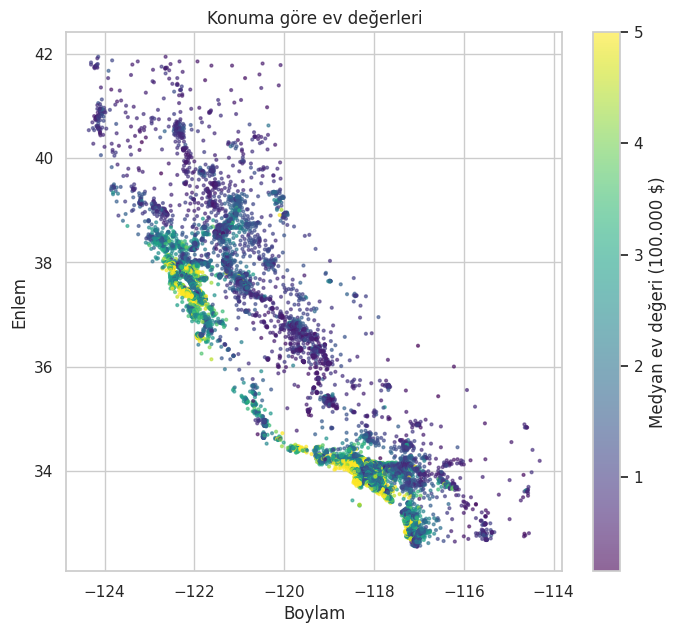

In [7]:
plt.figure(figsize=(8, 7))
plt.scatter(df["boylam"], df["enlem"], c=df["ev_degeri"], cmap="viridis", s=4, alpha=0.6)
plt.colorbar(label="Medyan ev değeri (100.000 $)")
plt.title("Konuma göre ev değerleri")
plt.xlabel("Boylam")
plt.ylabel("Enlem")
plt.show()


### Korelasyon

Korelasyon katsayısı iki sütunun birlikte nasıl değiştiğini −1 ile +1 arasında bir sayıyla gösterir:
- +1'e yakın: biri artarken diğeri de artar
- −1'e yakın: biri artarken diğeri azalır
- 0'a yakın: aralarında doğrusal bir ilişki yok

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasyon matrisi")
plt.show()

`ev_degeri` satırına bakıldığında en yüksek korelasyon `gelir` ile (yaklaşık 0,69). Diğer özelliklerin ev değeriyle doğrusal ilişkisi zayıf görünüyor. Ancak konum gibi özellikler doğrusal olmayan biçimde etkili olabilir; korelasyon sadece doğrusal ilişkiyi ölçer.

---
## 4. Tek özellikli doğrusal regresyon

Önce sadece **gelir** bilgisini kullanarak ev değerini tahmin edelim. Doğrusal regresyon şu biçimde bir doğru bulur:

**ev değeri = a × gelir + b**

- **a (eğim):** Gelir bir birim arttığında ev değerinin ne kadar arttığı
- **b (sabit):** Doğrunun dikey ekseni kestiği nokta

a ve b modelin veriden öğrendiği **parametrelerdir**. Model, tahmin hatalarının karelerinin toplamını en küçük yapan a ve b değerlerini bulur.

In [ ]:
X_tek = df[["gelir"]]      # tek özellik (çift köşeli parantez: sonuç tablo olarak kalsın)
y = df["ev_degeri"]        # etiket

X_tek_train, X_tek_test, y_train, y_test = train_test_split(X_tek, y, test_size=0.2, random_state=42)

lr_tek = LinearRegression()
lr_tek.fit(X_tek_train, y_train)

a = lr_tek.coef_[0]
b = lr_tek.intercept_
print(f"Öğrenilen eğim (a) : {a:.3f}")
print(f"Öğrenilen sabit (b): {b:.3f}")
print()
print(f"Yorum: Medyan gelir 10.000 $ arttığında, ev değeri ortalama {a * 100_000:,.0f} $ artıyor.")

In [ ]:
ornek = X_tek_test.sample(2000, random_state=1)
plt.scatter(ornek["gelir"], y_test.loc[ornek.index], alpha=0.3, s=10, label="Gerçek değerler")

cizgi = pd.DataFrame({"gelir": np.linspace(0, 15, 100)})
plt.plot(cizgi["gelir"], lr_tek.predict(cizgi), color="red", linewidth=3, label="Modelin doğrusu")

plt.xlabel("Medyan gelir (10.000 $)")
plt.ylabel("Medyan ev değeri (100.000 $)")
plt.title("Doğrusal regresyon: veriye en iyi uyan doğru")
plt.legend()
plt.show()

Kırmızı doğru, modelin öğrendiği ilişkidir. Noktaların doğru etrafında oldukça dağınık olması, tek bir özelliğin ev değerini açıklamaya yetmediğini gösteriyor.

---
## 5. Tüm özelliklerle modeller ve regresyon ölçütleri

Şimdi 8 özelliğin hepsini kullanalım ve modelleri üç ölçütle karşılaştıralım:

| Ölçüt | Ne söyler? | İyi değer |
|---|---|---|
| **MAE** (ortalama mutlak hata) | Tahminler ortalama ne kadar şaşıyor? Birimi etiketle aynıdır. | 0'a yakın |
| **RMSE** (kök ortalama kare hata) | MAE'ye benzer ama büyük hataları daha çok cezalandırır | 0'a yakın |
| **R²** (belirlilik katsayısı) | Ev değerlerindeki farklılıkların ne kadarını açıklıyoruz? | 1'e yakın |

Etiketin birimi 100.000 $ olduğu için MAE ve RMSE'yi 100.000 ile çarparak dolara çeviriyoruz.

In [ ]:
X = df.drop(columns="ev_degeri")     # 8 özellik
y = df["ev_degeri"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Eğitim kümesi:", X_train.shape[0], "bölge")
print("Test kümesi  :", X_test.shape[0], "bölge")

In [12]:
def degerlendir(ad, model, sutunlar):
    """Modeli eğitim ve test verisinde ölçüp sonuçları tek satır olarak döndürür."""
    tahmin = model.predict(X_test[sutunlar])
    return {
        "Model": ad,
        "MAE ($)": mean_absolute_error(y_test, tahmin) * 100_000,
        "RMSE ($)": np.sqrt(mean_squared_error(y_test, tahmin)) * 100_000,
        "R² (test)": r2_score(y_test, tahmin),
        "R² (eğitim)": r2_score(y_train, model.predict(X_train[sutunlar])),
    }

tum_sutunlar = list(X.columns)

lr_tek = LinearRegression().fit(X_train[["gelir"]], y_train)    # sadece gelir
lr = LinearRegression().fit(X_train, y_train)                   # 8 özellik

sonuclar = [
    degerlendir("Doğrusal regresyon (sadece gelir)", lr_tek, ["gelir"]),
    degerlendir("Doğrusal regresyon (8 özellik)", lr, tum_sutunlar),
]
pd.DataFrame(sonuclar).round(3)

,Model,MAE ($),RMSE ($),R² (test),R² (eğitim)
0,Doğrusal regresyon (sadece gelir),62990.865,84209.012,0.459,0.477
1,Doğrusal regresyon (8 özellik),53320.013,74558.138,0.576,0.613


**Sonuçların yorumu**
- 8 özellikli doğrusal regresyonun MAE değeri yaklaşık 53.000 $: Model bir bölgenin medyan ev değerini ortalama bu kadar yanlış tahmin ediyor.
- R² yaklaşık 0,58: Ev değerlerindeki farklılıkların yaklaşık %58'i modelle açıklanabiliyor.
- Özellik eklemek sonucu iyileştirdi. Ancak doğrusal model ilişkileri düz çizgilerle temsil ettiği için haritada gördüğümüz kıyı etkisi gibi karmaşık ilişkileri tam yakalayamıyor.

Gerçek ve tahmin edilen değerleri karşılaştıralım. Mükemmel bir modelde bütün noktalar kırmızı kesikli çizginin üzerinde olurdu.

In [ ]:
tahmin_lr = lr.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, tahmin_lr, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], "r--", linewidth=2, label="Mükemmel tahmin")
plt.xlabel("Gerçek değer (100.000 $)")
plt.ylabel("Tahmin (100.000 $)")
plt.title("Doğrusal regresyon: gerçek ve tahmin")
plt.legend()
plt.show()

### Rastgele orman

**Rastgele orman** çok sayıda karar ağacından oluşur. Her ağaç verinin rastgele seçilmiş farklı bir parçasıyla eğitilir; sonuçta tüm ağaçların tahminlerinin ortalaması alınır. Doğrusal olmayan ilişkileri de yakalayabildiği için genellikle doğrusal regresyondan daha iyi sonuç verir.

- `n_estimators=100`: Ormandaki ağaç sayısı
- `n_jobs=-1`: Bilgisayarın tüm işlemci çekirdeklerini kullanarak hızlandırır

Bu hücrenin çalışması Colab'de 20-40 saniye sürebilir.

In [14]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

sonuclar.append(degerlendir("Rastgele orman (100 ağaç)", rf, tum_sutunlar))
tablo = pd.DataFrame(sonuclar).round(3)
tablo

,Model,MAE ($),RMSE ($),R² (test),R² (eğitim)
0,Doğrusal regresyon (sadece gelir),62990.865,84209.012,0.459,0.477
1,Doğrusal regresyon (8 özellik),53320.013,74558.138,0.576,0.613
2,Rastgele orman (100 ağaç),32754.257,50533.998,0.805,0.974


In [ ]:
plt.barh(tablo["Model"], tablo["R² (test)"], color=["#9BB5DB", "#2B5FA8", "#E07A2F"])
plt.xlabel("Test R² (1'e yakın olması daha iyi)")
plt.title("Modellerin test verisindeki R² değerleri")
plt.xlim(0, 1)
plt.show()

**Sonuçların yorumu**
- Rastgele orman test R² değerini yaklaşık 0,80'e çıkardı, MAE'yi yaklaşık 33.000 $'a düşürdü.
- Ancak **eğitim R²** sütununa dikkat edin: Rastgele orman eğitim verisinde yaklaşık 0,97, test verisinde 0,80 alıyor. Bu fark, modelin eğitim verisinin bir kısmını ezberlediğini gösteriyor. Bir sonraki adımda bu durumu ayrıntılı inceleyeceğiz.

---
## 6. Aşırı öğrenmeyi bir grafikte görmek

Tek bir karar ağacının **derinliğini** (sorabileceği ardışık soru sayısını) 1'den 25'e kadar artırıp her seferinde eğitim ve test R² değerlerini ölçelim. Derinlik arttıkça model daha karmaşık hâle gelir.

In [ ]:
derinlikler = range(1, 26)
egitim_r2 = []
test_r2 = []

for d in derinlikler:
    agac = DecisionTreeRegressor(max_depth=d, random_state=42)
    agac.fit(X_train, y_train)
    egitim_r2.append(agac.score(X_train, y_train))   # score, regresyon modellerinde R² döndürür
    test_r2.append(agac.score(X_test, y_test))

en_iyi_derinlik = derinlikler[int(np.argmax(test_r2))]

plt.figure(figsize=(9, 5))
plt.plot(derinlikler, egitim_r2, "o-", label="Eğitim R²")
plt.plot(derinlikler, test_r2, "s-", label="Test R²")
plt.axvline(en_iyi_derinlik, color="gray", linestyle="--", label=f"En iyi test sonucu: derinlik {en_iyi_derinlik}")
plt.axvspan(1, 4, alpha=0.08, color="blue")
plt.text(1.3, 0.15, "Yetersiz\nöğrenme", fontsize=11)
plt.axvspan(14, 25, alpha=0.08, color="red")
plt.text(17, 0.15, "Aşırı öğrenme", fontsize=11)
plt.xlabel("Ağaç derinliği (model karmaşıklığı)")
plt.ylabel("R²")
plt.title("Model karmaşıklığına göre eğitim ve test başarısı")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

print("En iyi test R² değeri:", round(max(test_r2), 3), "derinlik:", en_iyi_derinlik)

**Grafiğin yorumu**
- **Derinlik 1-4:** Ağaç çok basit; hem eğitim hem test başarısı düşük. Bu **yetersiz öğrenmedir**.
- **Derinlik 5-9:** İki eğri birlikte yükseliyor; model veriden genel kuralları öğreniyor. Test başarısı derinlik 9 civarında en yüksek değerine ulaşıyor.
- **Derinlik 10 ve sonrası:** Eğitim R² 1'e doğru yükselmeye devam ederken test R² yavaş yavaş düşüyor. Derinlik 25'te eğitim R² 1,0'a ulaşıyor: Ağaç eğitim verisindeki her bölgeyi ezberlemiş. Bu **aşırı öğrenmedir**.

Bir modeli seçerken eğitim başarısına değil, modelin görmediği verideki başarısına bakarız.

---
## 7. Hangi özellikler önemli?

Rastgele orman, her özelliğin tahminlere ne kadar katkı sağladığını hesaplayabilir. Bu değerlere **özellik önemi** (feature importance) denir ve toplamları 1'dir.

In [ ]:
onem = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
onem.plot(kind="barh", color="#2B5FA8")
plt.title("Rastgele orman: özelliklerin önemi")
plt.xlabel("Önem payı (toplam = 1)")
plt.show()

En önemli özellik **gelir**; ardından **konum** (enlem ve boylam) ve **hane büyüklüğü** geliyor. Bu sonuç görselleştirme aşamasındaki gözlemlerimizle uyumlu.

Özellik önemi nedensellik göstermez. "Gelir ev değerini artırır" anlamına gelmez; "gelir bilgisi, tahmin yaparken en çok işe yarayan bilgidir" anlamına gelir.

---
## 8. Yeni bir bölge için tahmin

Özelliklerini bildiğimiz yeni bir bölge için iki modelin tahminine bakalım.

In [ ]:
yeni_bolge = pd.DataFrame([{
    "gelir": 6.0,             # 60.000 $ medyan gelir
    "ev_yasi": 20,
    "oda_sayisi": 6.0,
    "yatak_odasi": 1.0,
    "nufus": 1200,
    "hane_buyuklugu": 2.8,
    "enlem": 37.77,           # San Francisco civarı
    "boylam": -122.42,
}])

for ad, m in [("Doğrusal regresyon", lr), ("Rastgele orman", rf)]:
    tahmin = m.predict(yeni_bolge)[0] * 100_000
    print(f"{ad:20s} tahmini medyan ev değeri: {tahmin:,.0f} $")

Aynı bölgeyi iç kesimlere taşımak için `enlem` ve `boylam` değerlerini örneğin Fresno şehrinin koordinatlarıyla (36.74, -119.79) değiştirip hücreyi tekrar çalıştırın. Gelir aynı kaldığı hâlde tahminin nasıl değiştiğini gözlemleyin.

---
## Özet

| Kavram | Bu uygulamada |
|---|---|
| Hazır veri seti | `fetch_california_housing` ile tek satırda yüklendi |
| Regresyon | Etiket bir sayı: medyan ev değeri |
| Parametre | Doğrusal regresyonun öğrendiği eğim (a) ve sabit (b) |
| MAE, RMSE, R² | Doğrusal regresyon: MAE ≈ 53.000 $, R² ≈ 0,58 · Rastgele orman: MAE ≈ 33.000 $, R² ≈ 0,80 |
| Aşırı öğrenme | Derin ağaç: eğitim R² 1,0'a çıkarken test R² düşüyor |
| Özellik önemi | Gelir, konum ve hane büyüklüğü öne çıkıyor |

### Tartışma soruları
1. Bu model bugün bir ev alırken fiyat tahmini için kullanılabilir mi? Neden?
2. Ev değerindeki 500.000 $ üst sınırı modelin tahminlerini nasıl etkileyebilir?
3. Eğitim başarısının test başarısından genellikle daha yüksek çıkmasının nedeni nedir?

### Deneyebilecekleriniz
- Rastgele ormanda `max_depth=8` parametresini ekleyin. Eğitim ve test R² farkı nasıl değişti?
- `n_estimators` değerini 10 ve 200 yapın. Çalışma süresi ve başarı nasıl değişti?
- Doğrusal regresyonu sadece `gelir`, `enlem` ve `boylam` ile kurun. R² ne oldu?